# 1. Framing the Problem

Objective: The goal is to estimate the price per unit area of a house from basic facts about this house: how old it is, its location, the nearest metro (MRT) station, and the number of convenience stores nearby. This dataset could be used by buyers and sellers to check whether prices are reasonable.

Data description: Each row represents one sale (414 sales in total). The target to predict is the house price per unit area. The features are the transaction date, house age, distance to the nearest MRT station, number of nearby convenience stores, latitude and longitude.

How the solution will be used: This data may be used as a quick price check that can help support a purchasing or selling decisions, whenever someone wants to compare an asking price with an estimate.

Current solutions: People usually compare the price of a house with similar nearby sales or rely on an agent's or appraiser's judgment, which can be slow and subjective. A model can apply similar objective assessments to every house.

Type of problem: This is supervised learning (the data contains known prices to learn from), regression (the target is a number), and offline learning (the data is fixed) 

Performance measure: I will use RMSE (root mean squared error). It is the typical size of the model's mistakes, in the same units as the price, and it penalizes large mistakes more than small ones. 

Measure's alignment with the business objective: They are aligned. For a price check, large errors are the costly ones (someone could overpay a lot), and RMSE punishes large errors more heavily.

Minimum performance: The dataset has no business threshold, so I use a baseline: a model that always predicts the average price. Its error is about the spread of the prices, roughly 13.6 in this dataset. 

Comparable problems: This is similar to the California housing example (predicting house value from location and neighborhood features), so I can reuse its overall approach and adapt it.

Human expertise: An agent or appraiser would also consider factors that this data does not contain, such as the condition of the house, floor level, number of rooms, etc. This limits how accurate any model built on this data can be.

Source: https://archive.ics.uci.edu/dataset/477/real+estate+valuation+data+set

# 2. Data Acquisition

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_excel("Real_estate_valuation_data_set.xlsx")
df.columns = ["No", "Date", "Age", "MRT_distance", "Stores", "Lat", "Lon", "Price"]
df = df.drop(columns="No")

### Quick Look at the Data Structure

In [3]:
df.head()

,Date,Age,MRT_distance,Stores,Lat,Lon,Price
0,2012.916667,32.0,84.87882,10,24.98298,121.54024,37.9
1,2012.916667,19.5,306.59470,9,24.98034,121.53951,42.2
2,2013.583333,13.3,561.98450,5,24.98746,121.54391,47.3
3,2013.500000,13.3,561.98450,5,24.98746,121.54391,54.8
4,2012.833333,5.0,390.56840,5,24.97937,121.54245,43.1


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Date          414 non-null    float64
 1   Age           414 non-null    float64
 2   MRT_distance  414 non-null    float64
 3   Stores        414 non-null    int64  
 4   Lat           414 non-null    float64
 5   Lon           414 non-null    float64
 6   Price         414 non-null    float64
dtypes: float64(6), int64(1)
memory usage: 22.8 KB


In [5]:
df.describe()

,Date,Age,MRT_distance,Stores,Lat,Lon,Price
count,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000
mean,2013.148953,17.712560,1083.885689,4.094203,24.969030,121.533361,37.980193
std,0.281995,11.392485,1262.109595,2.945562,0.012410,0.015347,13.606488
min,2012.666667,0.000000,23.382840,0.000000,24.932070,121.473530,7.600000
25%,2012.916667,9.025000,289.324800,1.000000,24.963000,121.528085,27.700000
50%,2013.166667,16.100000,492.231300,4.000000,24.971100,121.538630,38.450000
75%,2013.416667,28.150000,1454.279000,6.000000,24.977455,121.543305,46.600000
max,2013.583333,43.800000,6488.021000,10.000000,25.014590,121.566270,117.500000


### Create a Test Set 

In [6]:
# Houses sorted into distance groups

df["MRT_cat"] = pd.cut(df["MRT_distance"],
                       bins=[0., 250, 500, 1000, 2000, np.inf],
                       labels=[1, 2, 3, 4, 5])

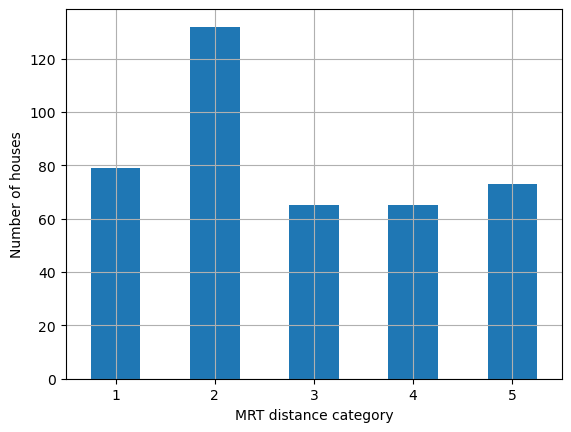

In [7]:
# Checking the groups

df["MRT_cat"].value_counts().sort_index().plot.bar(rot=0, grid=True)
plt.xlabel("MRT distance category")
plt.ylabel("Number of houses")
plt.show()

In [8]:
# Splitting into training and test sets

from sklearn.model_selection import train_test_split

train_set, test_set = train_test_split(
    df, test_size=0.2, stratify=df["MRT_cat"], random_state=42)

In [9]:
print(len(train_set), len(test_set))

331 83


In [10]:
test_set["MRT_cat"].value_counts() / len(test_set)

MRT_cat
2    0.313253
1    0.192771
5    0.180723
3    0.156627
4    0.156627
Name: count, dtype: float64

In [11]:
# Remove MRT category
for set_ in (train_set, test_set):
    set_.drop("MRT_cat", axis=1, inplace=True)

I set aside 20% of the houses (83 houses) as a test set, which will be used for the final evaluation. I used scikit-learn's train_test_split with a fixed random seed so the split is reproducible. I stratified on distance to the nearest MRT station so that the test set has a similar mix of near and far houses as the training set.

# 3. Data Exploration

In [12]:
houses = train_set.copy()

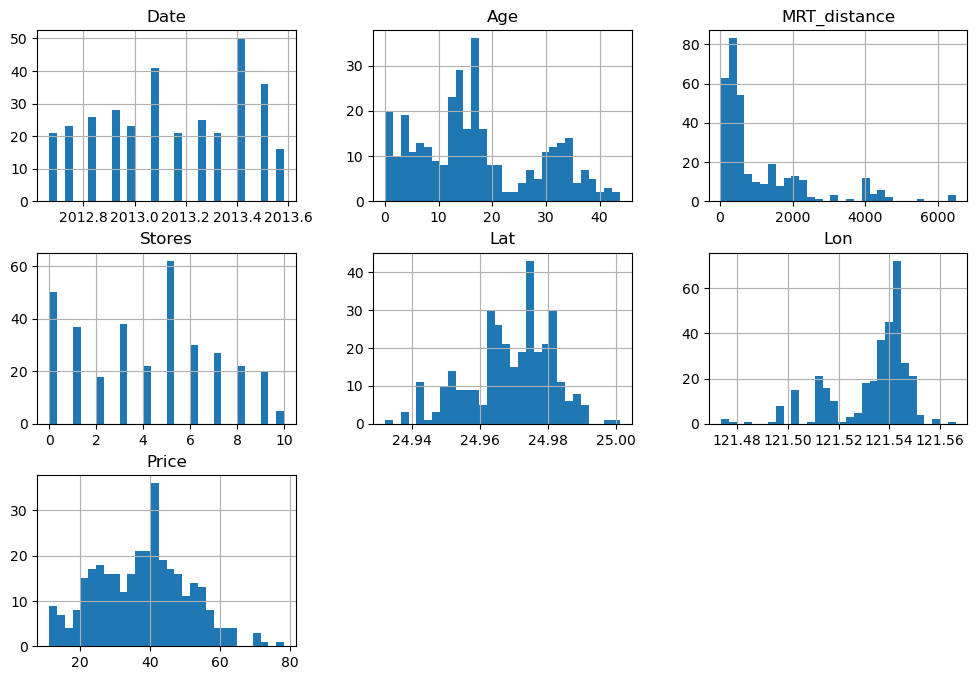

In [13]:
houses.hist(bins=30, figsize=(12, 8))
plt.show()

### Visualizing Geographical Data

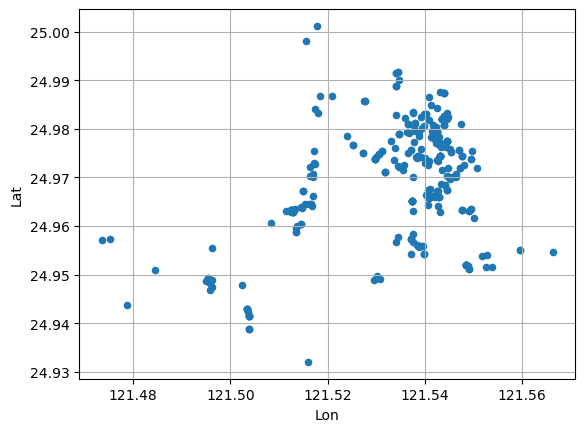

In [14]:
houses.plot(kind="scatter", x="Lon", y="Lat", grid=True)
plt.show()

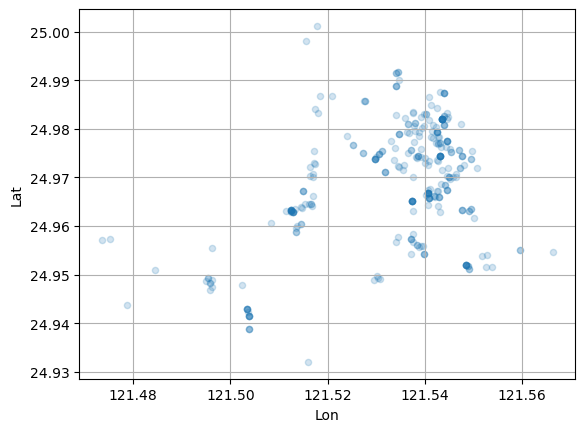

In [15]:
houses.plot(kind="scatter", x="Lon", y="Lat", grid=True, alpha=0.2)
plt.show()

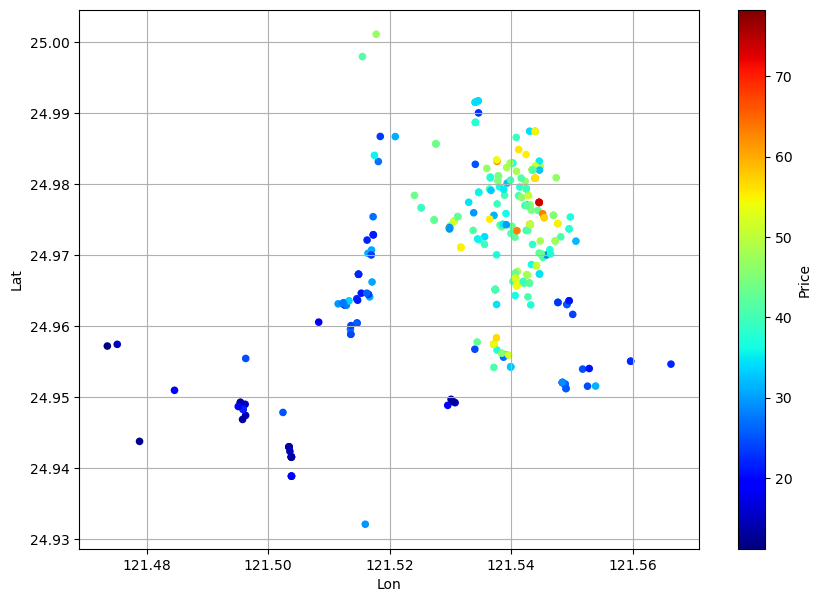

In [16]:
houses.plot(kind="scatter", x="Lon", y="Lat", grid=True,
            c="Price", cmap="jet", colorbar=True, legend=True, figsize=(10, 7))
plt.show()

Most houses are gathered in one central-northern cluster, and that cluster contains the most expensive houses (from green/yellow to red). Houses toward the outer edges, especially to the west and south, are mostly cheaper (blue). This matches the positive correlations with latitude and longitude.


### Looking for Correlations

In [17]:
corr_matrix = houses.corr(numeric_only=True)

In [18]:
corr_matrix["Price"].sort_values(ascending=False)

Price           1.000000
Stores          0.624442
Lat             0.591854
Lon             0.581827
Date            0.076972
Age            -0.291069
MRT_distance   -0.719508
Name: Price, dtype: float64

- 'MRT_distance' is the strongest evidence: houses closer to the metro station are clearly more expensive (-0.72). 
- 'Stores' is also a strong predictor: price tends to rise with the number of nearby convenience stores (+0.62). 
- 'Lat' and 'Lon' also matter (+0.59 and +0.58), showing that location affects price.
- 'Date' has almost no relationship with price (+0.08). 
- 'Age' has a weak negative relationship (-0.29) and its scatter plots confirms that age alone doesn't predict price well. 
- 'MRT_distance' is also heavily skewed: most houses are close to a station and a few are very far.


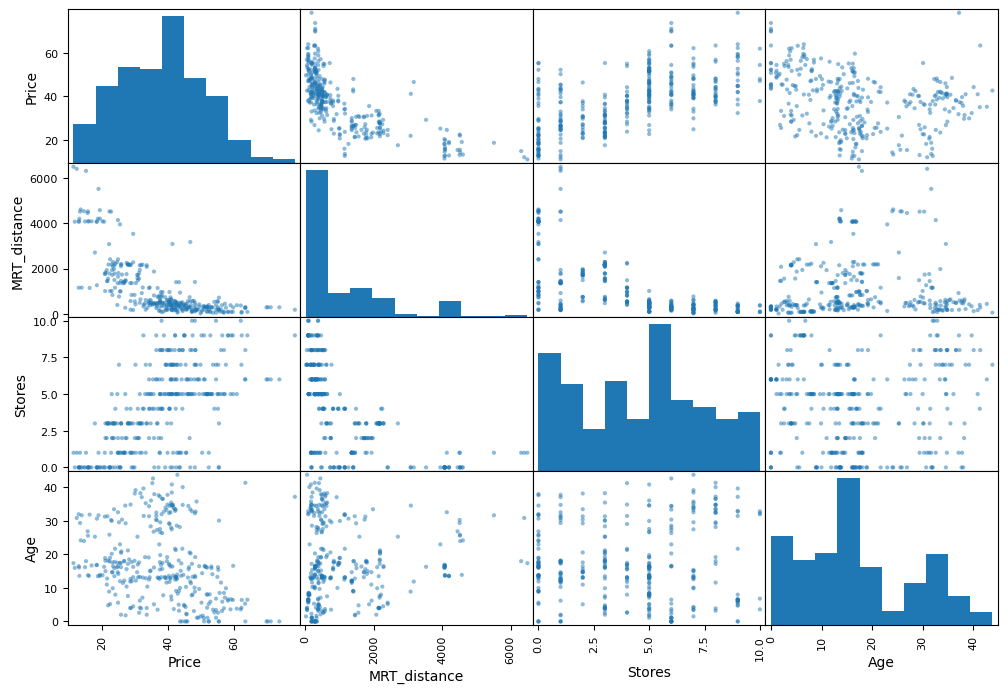

In [19]:
from pandas.plotting import scatter_matrix

attributes = ["Price", "MRT_distance", "Stores", "Age"]
scatter_matrix(houses[attributes], figsize=(12, 8))
plt.show()

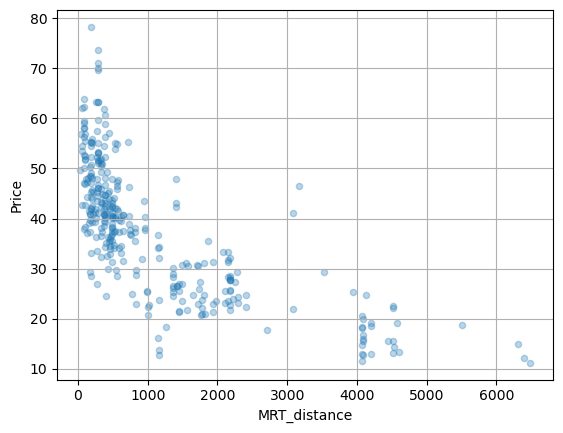

In [20]:
houses.plot(kind="scatter", x="MRT_distance", y="Price", alpha=0.3, grid=True)
plt.show()

### Experimenting with Attribute Combinations

In [21]:
houses["log_MRT_distance"] = np.log(houses["MRT_distance"])
houses.corr(numeric_only=True)["Price"].sort_values(ascending=False)

Price               1.000000
Stores              0.624442
Lat                 0.591854
Lon                 0.581827
Date                0.076972
Age                -0.291069
MRT_distance       -0.719508
log_MRT_distance   -0.781113
Name: Price, dtype: float64

The log of 'MRT_distance' is more strongly correlated with price (-0.78) than the raw distance (-0.72). The scatter plot shows price decreasing sharply over short distances and then becoming flat. The log allows to stretch the crowded short distances and squeeze the long ones, so the relationship gets closer to a straight line. Using the log of the distance in data preparation is then a good fit, especially for linear models.


# 4. Data Preparation

Here, I prepare the training data for the models. I separate the features from the price, check for missing values and outliers, rescale the columns, and combine everything into one pipeline. A pipeline applies exactly the same steps to any house later, including the test houses. I only use the training set here, and the test set stays untouched.

In [22]:
houses = train_set.drop("Price", axis=1)
houses_labels = train_set["Price"].copy()

#### Data Cleaning

Here, I checked for rows with missing values (found none), so I don't need to drop rows or fill gaps. I still ran the notebook's 'SimpleImputer' (median strategy) to see how it works. The table it returns is identical to the original, because there was nothing to fill. I keep it inside the pipeline as a safeguard in case new data has gaps. All six columns are numeric, so I skip the notebook's steps for text and categorical columns.

In [23]:
# Lists rows with an empty cell (here, none)
null_rows_idx = houses.isnull().any(axis=1)
houses.loc[null_rows_idx].head()

,Date,Age,MRT_distance,Stores,Lat,Lon


In [24]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

In [25]:
houses_num = houses.select_dtypes(include=[np.number])

In [26]:
imputer.fit(houses_num)

,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False


In [27]:
imputer.statistics_

array([2013.1666667,   15.6      ,  492.2313   ,    5.       ,
         24.9711   ,  121.53913  ])

In [28]:
houses_num.median().values

array([2013.1666667,   15.6      ,  492.2313   ,    5.       ,
         24.9711   ,  121.53913  ])

In [29]:
X = imputer.transform(houses_num)

In [30]:
houses_tr = pd.DataFrame(X, columns=houses_num.columns, index=houses_num.index)

The notebook uses 'IsolationForest' to flag unusual rows -> it flagged 80 of 331 houses (about a quarter of the training data) which is too many to call real outliers. The notebook itself only shows the code for dropping outliers as a comment, so I kept all the houses.

In [31]:
from sklearn.ensemble import IsolationForest

isolation_forest = IsolationForest(random_state=42)
outlier_pred = isolation_forest.fit_predict(X)

In [32]:
outlier_pred

array([ 1,  1,  1,  1,  1,  1,  1, -1,  1, -1,  1,  1,  1,  1, -1, -1,  1,
        1,  1,  1, -1,  1,  1,  1,  1,  1,  1,  1, -1,  1,  1, -1,  1,  1,
        1, -1, -1,  1,  1,  1,  1, -1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
       -1, -1,  1,  1, -1,  1,  1,  1,  1,  1, -1,  1,  1,  1,  1, -1,  1,
        1,  1,  1,  1,  1, -1,  1,  1,  1,  1,  1,  1,  1, -1,  1,  1,  1,
        1,  1, -1,  1,  1,  1,  1,  1,  1,  1,  1, -1, -1, -1,  1,  1,  1,
        1,  1, -1,  1,  1,  1,  1, -1,  1,  1, -1,  1,  1,  1,  1, -1, -1,
        1,  1,  1,  1,  1, -1,  1,  1,  1,  1,  1,  1,  1,  1, -1,  1,  1,
        1,  1, -1,  1,  1,  1, -1,  1, -1, -1,  1,  1,  1,  1,  1, -1,  1,
        1,  1, -1,  1,  1,  1, -1,  1,  1,  1,  1, -1, -1, -1,  1,  1,  1,
        1,  1, -1,  1, -1,  1,  1,  1,  1, -1, -1,  1, -1,  1,  1,  1,  1,
        1,  1,  1, -1,  1,  1,  1,  1,  1,  1,  1, -1, -1,  1,  1, -1, -1,
        1,  1,  1,  1,  1,  1, -1,  1,  1,  1, -1,  1,  1,  1,  1,  1, -1,
       -1, -1,  1, -1, -1

In [33]:
(outlier_pred == -1).sum()

np.int64(80)

#### Feature Scaling

My columns are on very different scales -> distance goes into the thousands, stores goes from 0 to 10, and latitude and longitude vary only in the second or third decimal place. I tried 'MinMaxScaler' and 'StandardScaler', and I use 'StandardScaler' in the pipeline, as the notebook does.

In [34]:
# Squeeze each column into -1 to 1
from sklearn.preprocessing import MinMaxScaler

min_max_scaler = MinMaxScaler(feature_range=(-1, 1))
houses_num_min_max_scaled = min_max_scaler.fit_transform(houses_num)

In [35]:
# Center each column at 0 with spread of 1
from sklearn.preprocessing import StandardScaler

std_scaler = StandardScaler()
houses_num_std_scaled = std_scaler.fit_transform(houses_num)

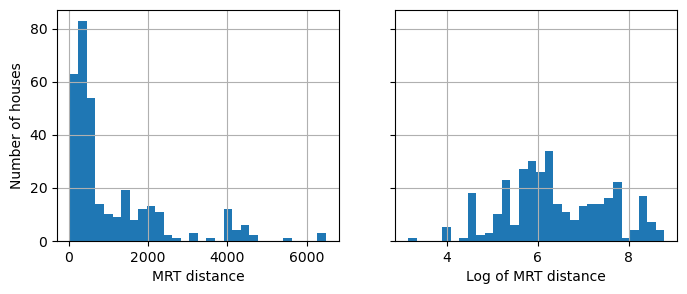

In [36]:
fig, axs = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
houses["MRT_distance"].hist(ax=axs[0], bins=30)
houses["MRT_distance"].apply(np.log).hist(ax=axs[1], bins=30)
axs[0].set_xlabel("MRT distance")
axs[1].set_xlabel("Log of MRT distance")
axs[0].set_ylabel("Number of houses")
plt.show()

MRT_distance has a long tail, showing that most houses are close to a station and a few are very far. Its skew drops from about 1.9 to 0.1 after taking the log, so the log makes it close to symmetric. The log also had a stronger correlation with price than the raw distance. I apply the log to this column inside the pipeline.

#### Custom Transformers

In [37]:
# Wrap the log func so it can be used as a step in a pipeline
from sklearn.preprocessing import FunctionTransformer

log_transformer = FunctionTransformer(np.log, inverse_func=np.exp)
log_mrt = log_transformer.transform(houses[["MRT_distance"]])

In [38]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import rbf_kernel

class ClusterSimilarity(BaseEstimator, TransformerMixin):
    def __init__(self, n_clusters=10, gamma=1.0, random_state=None):
        self.n_clusters = n_clusters
        self.gamma = gamma
        self.random_state = random_state

    def fit(self, X, y=None, sample_weight=None):
        self.kmeans_ = KMeans(self.n_clusters, n_init=10,
                              random_state=self.random_state)
        self.kmeans_.fit(X, sample_weight=sample_weight)
        return self  # always return self!

    def transform(self, X):
        return rbf_kernel(X, self.kmeans_.cluster_centers_, gamma=self.gamma)

    def get_feature_names_out(self, names=None):
        return [f"Cluster {i} similarity" for i in range(self.n_clusters)]

# Finds 10 typical spots (clusters of houses), measure how close each house is to each spot, from 1 (closer) to 0 (further).

In [39]:
cluster_simil = ClusterSimilarity(n_clusters=10, gamma=1000., random_state=42)
similarities = cluster_simil.fit_transform(houses[["Lat", "Lon"]])

In [40]:
similarities[:3].round(2)

array([[0.4 , 0.99, 0.48, 0.49, 0.41, 0.54, 0.71, 0.21, 0.21, 0.61],
       [0.76, 0.77, 0.67, 0.2 , 0.7 , 0.55, 0.95, 0.06, 0.28, 0.85],
       [0.97, 0.36, 0.85, 0.06, 0.98, 0.55, 0.88, 0.01, 0.49, 0.57]])

Gives 10 columns per house (values between 0 and 1).

The notebook uses gamma = 1 (gamma = controls how quickly similarity drops with distance), which suits California's coordinates, but mine cover a much smaller area, so gamma = 1 led to every house coming out similar to every cluster (99% or +), which tells the model nothing. Therefore, I used gamma = 1000, which gives well-spread values.

#### Encoding Methods (demonstration)

My data has no categorical columns, so encoding isn't needed for the model. To demonstrate the methods, I apply one-hot and ordinal encoding to a small made-up categorical column.

In [72]:
demo = pd.DataFrame({"orientation": ["north", "south", "east", "west", "north"]})

from sklearn.preprocessing import OneHotEncoder
onehot = OneHotEncoder(sparse_output=False)
onehot.fit_transform(demo)

array([[0., 1., 0., 0.],
       [0., 0., 1., 0.],
       [1., 0., 0., 0.],
       [0., 0., 0., 1.],
       [0., 1., 0., 0.]])

In [73]:
from sklearn.preprocessing import OrdinalEncoder
ordinal = OrdinalEncoder()
ordinal.fit_transform(demo)

array([[1.],
       [2.],
       [0.],
       [3.],
       [1.]])

One-hot encoding would suit a column like this, since there's no natural order between categories. Ordinal encoding wouldn't suit it, since it would imply an order (north < south < east < west) that doesn't exist in the data.

#### Transformation Pipelines

A pipeline chains preparation steps into one object. I built 2: one that fills gaps, takes the log, and rescales (for 'MRT_distance'), and one that fills gaps and rescales, for the other numeric columns. A 'ColumnTransformer' sends each column to the right pipeline -> 'MRT_distance' goes through the log pipeline, 'Lat' and 'Lon' go through the cluster similarity, and 'Date', 'Age', and 'Stores' go through the default pipeline.

In [41]:
from sklearn.pipeline import make_pipeline

num_pipeline = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())

In [42]:
houses_num_prepared = num_pipeline.fit_transform(houses_num)
houses_num_prepared[:2].round(2)

array([[ 0.37,  0.06,  0.55, -0.39, -0.14, -1.19],
       [-0.23, -0.39, -0.28, -1.44,  0.62, -0.53]])

In [43]:
from sklearn.compose import ColumnTransformer

log_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    FunctionTransformer(np.log, feature_names_out="one-to-one"),
    StandardScaler())
default_num_pipeline = make_pipeline(SimpleImputer(strategy="median"),
                                     StandardScaler())
preprocessing = ColumnTransformer([
        ("log", log_pipeline, ["MRT_distance"]),
        ("geo", cluster_simil, ["Lat", "Lon"]),
    ],
    remainder=default_num_pipeline)  # remaining columns --> Date, Age, Stores

# Sends MRT_distance through the log pipeline, Lat and Lon through the cluster similarity, and everything else (Date, Age, Stores) through the default numeric pipeline.

In [44]:
houses_prepared = preprocessing.fit_transform(houses)
houses_prepared.shape

(331, 14)

The prepared training data has 331 houses and 14 columns -> 1 log-distance column, 10 cluster-similarity columns, and 3 remaining columns ('Date', 'Age', 'Stores').

In [45]:
preprocessing.get_feature_names_out()

array(['log__MRT_distance', 'geo__Cluster 0 similarity',
       'geo__Cluster 1 similarity', 'geo__Cluster 2 similarity',
       'geo__Cluster 3 similarity', 'geo__Cluster 4 similarity',
       'geo__Cluster 5 similarity', 'geo__Cluster 6 similarity',
       'geo__Cluster 7 similarity', 'geo__Cluster 8 similarity',
       'geo__Cluster 9 similarity', 'remainder__Date', 'remainder__Age',
       'remainder__Stores'], dtype=object)

# 5. Modelling


#### Training and Evaluating on the Training Set

In [46]:
from sklearn.linear_model import LinearRegression

lin_reg = make_pipeline(preprocessing, LinearRegression())
lin_reg.fit(houses, houses_labels)

,steps,"[('columntransformer', ...), ('linearregression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('log', ...), ('geo', ...)]"
,remainder,Pipeline(step...ardScaler())])
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [47]:
houses_predictions = lin_reg.predict(houses)
houses_predictions[:5].round(1)

array([26.7, 36.8, 48.2, 37.6, 48.5])

In [48]:
houses_labels.iloc[:5].values

array([23.7, 40.6, 49.3, 40.6, 51.7])

In [49]:
# Error ratios
error_ratios = houses_predictions[:5].round(1) / houses_labels.iloc[:5].values - 1
print(", ".join([f"{100 * ratio:.1f}%" for ratio in error_ratios]))

12.7%, -9.4%, -2.2%, -7.4%, -6.2%


In [50]:
try:
    from sklearn.metrics import root_mean_squared_error
except ImportError:
    from sklearn.metrics import mean_squared_error

    def root_mean_squared_error(labels, predictions):
        return mean_squared_error(labels, predictions, squared=False)

lin_rmse = root_mean_squared_error(houses_labels, houses_predictions)
lin_rmse

5.976459273593105

Linear regression's training error (5.97) is close to what cross-validation later shows, which is an early sign it isn't overfitting.

In [51]:
from sklearn.tree import DecisionTreeRegressor

tree_reg = make_pipeline(preprocessing, DecisionTreeRegressor(random_state=42))
tree_reg.fit(houses, houses_labels)

,steps,"[('columntransformer', ...), ('decisiontreeregressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('log', ...), ('geo', ...)]"
,remainder,Pipeline(step...ardScaler())])
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [52]:
houses_predictions = tree_reg.predict(houses)
tree_rmse = root_mean_squared_error(houses_labels, houses_predictions)
tree_rmse

0.8242455123642275

The tree's training error (about 0.8) is almost zero, which looks too good -> a model that predicts its own training data nearly perfectly usually hasn't learned a general pattern, it has memorized the answers, so cross-validation below will show whether that's true.

#### Better Evaluation Using Cross-Validation

In [53]:
from sklearn.model_selection import cross_val_score

tree_rmses = -cross_val_score(tree_reg, houses, houses_labels,
                              scoring="neg_root_mean_squared_error", cv=10)

In [54]:
pd.Series(tree_rmses).describe()

count    10.000000
mean      7.345783
std       2.480016
min       4.453157
25%       5.288163
50%       6.605595
75%       9.684744
max      10.963341
dtype: float64

In [55]:
# extra code – computes the error stats for the linear model
lin_rmses = -cross_val_score(lin_reg, houses, houses_labels,
                              scoring="neg_root_mean_squared_error", cv=10)
pd.Series(lin_rmses).describe()

count    10.000000
mean      6.227600
std       1.215062
min       4.630447
25%       5.485156
50%       5.932377
75%       7.216880
max       8.197378
dtype: float64

In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Random forest tends to overfit less than a single tree, since it averages many trees

forest_reg = make_pipeline(preprocessing,
                           RandomForestRegressor(random_state=42))
forest_rmses = -cross_val_score(forest_reg, houses, houses_labels,
                                scoring="neg_root_mean_squared_error", cv=10)

In [57]:
pd.Series(forest_rmses).describe()

count    10.000000
mean      5.651043
std       1.086085
min       4.428867
25%       4.952712
50%       5.229672
75%       6.069815
max       8.024285
dtype: float64

In [58]:
forest_reg.fit(houses, houses_labels)
houses_predictions = forest_reg.predict(houses)
forest_rmse = root_mean_squared_error(houses_labels, houses_predictions)
forest_rmse

2.252649799420325

This is the classic overfitting pattern, where the tree fits the training data almost perfectly (low bias) but its cross-validation score jumps around a lot between folds (high variance, std about 2.5), so it doesn't generalize well. The forest reduces this by averaging many trees.

# 6. Model Fine-Tuning

I now tune the settings of the model I chose, the random forest. I tune 2: the number of clusters in my location transformer, and 'max_features', the number of columns each tree may consider at each split. Cross-validation decides which values work best.

#### Grid Search

Grid search tries every combination in a list, using 3-fold cross-validation --> result: the best was 5 clusters with 'max_features' of 4, with an RMSE of about 5.71 (several other combinations scored almost the same, so the choice doesn't matter much)

In [59]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

full_pipeline = Pipeline([
    ("preprocessing", preprocessing),
    ("random_forest", RandomForestRegressor(random_state=42)),
])
param_grid = [
    {'preprocessing__geo__n_clusters': [5, 8, 10],
     'random_forest__max_features': [4, 6, 8]},
    {'preprocessing__geo__n_clusters': [10, 15],
     'random_forest__max_features': [6, 8, 10]},
]
grid_search = GridSearchCV(full_pipeline, param_grid, cv=3,
                           scoring='neg_root_mean_squared_error')
grid_search.fit(houses, houses_labels)

,estimator,Pipeline(step...m_state=42))])
,param_grid,"[{'preprocessing__geo__n_clusters': [5, 8, ...], 'random_forest__max_features': [4, 6, ...]}, {'preprocessing__geo__n_clusters': [10, 15], 'random_forest__max_features': [6, 8, ...]}]"
,scoring,'neg_root_mean_squared_error'
,n_jobs,None
,refit,True
,cv,3
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('log', ...), ('geo', ...)]"


In [60]:
print(str(full_pipeline.get_params().keys())[:1000] + "...")

dict_keys(['memory', 'steps', 'transform_input', 'verbose', 'preprocessing', 'random_forest', 'preprocessing__force_int_remainder_cols', 'preprocessing__n_jobs', 'preprocessing__remainder__memory', 'preprocessing__remainder__steps', 'preprocessing__remainder__transform_input', 'preprocessing__remainder__verbose', 'preprocessing__remainder__simpleimputer', 'preprocessing__remainder__standardscaler', 'preprocessing__remainder__simpleimputer__add_indicator', 'preprocessing__remainder__simpleimputer__copy', 'preprocessing__remainder__simpleimputer__fill_value', 'preprocessing__remainder__simpleimputer__keep_empty_features', 'preprocessing__remainder__simpleimputer__missing_values', 'preprocessing__remainder__simpleimputer__strategy', 'preprocessing__remainder__standardscaler__copy', 'preprocessing__remainder__standardscaler__with_mean', 'preprocessing__remainder__standardscaler__with_std', 'preprocessing__remainder', 'preprocessing__sparse_threshold', 'preprocessing__transformer_weights', 

In [61]:
grid_search.best_params_

{'preprocessing__geo__n_clusters': 5, 'random_forest__max_features': 4}

In [62]:
grid_search.best_estimator_

,steps,"[('preprocessing', ...), ('random_forest', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('log', ...), ('geo', ...)]"
,remainder,Pipeline(step...ardScaler())])
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [63]:
cv_res = pd.DataFrame(grid_search.cv_results_)
cv_res.sort_values(by="mean_test_score", ascending=False, inplace=True)

# extra code – these few lines of code just make the DataFrame look nicer
cv_res = cv_res[["param_preprocessing__geo__n_clusters",
                 "param_random_forest__max_features", "split0_test_score",
                 "split1_test_score", "split2_test_score", "mean_test_score"]]
score_cols = ["split0", "split1", "split2", "mean_test_rmse"]
cv_res.columns = ["n_clusters", "max_features"] + score_cols
cv_res[score_cols] = -cv_res[score_cols].round(2)

cv_res.head()

,n_clusters,max_features,split0,split1,split2,mean_test_rmse
0,5,4,6.02,5.25,5.85,5.71
1,5,6,6.10,5.20,5.87,5.73
11,10,10,6.09,5.60,5.58,5.76
4,8,6,6.12,5.49,5.68,5.77
5,8,8,6.14,5.59,5.63,5.79


#### Randomized Search

Randomized search tries random combinations from ranges instead of a fixed grid --> result: tt found 9 clusters and 'max_features' of 5, with an RMSE of about 5.79, essentially the same as grid search. Following the notebook, I use the best model from the randomized search as my final model. I changed the ranges from the notebook because 'max_features' cannot exceed the number of columns, and my data has far fewer columns than the California data.

In [64]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

param_distribs = {'preprocessing__geo__n_clusters': randint(low=3, high=30),
                  'random_forest__max_features': randint(low=2, high=8)}

rnd_search = RandomizedSearchCV(
    full_pipeline, param_distributions=param_distribs, n_iter=10, cv=3,
    scoring='neg_root_mean_squared_error', random_state=42)

rnd_search.fit(houses, houses_labels)

,estimator,Pipeline(step...m_state=42))])
,param_distributions,"{'preprocessing__geo__n_clusters': <scipy.stats....t 0x17870da90>, 'random_forest__max_features': <scipy.stats....t 0x1787d3110>}"
,n_iter,10
,scoring,'neg_root_mean_squared_error'
,n_jobs,None
,refit,True
,cv,3
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [65]:
cv_res = pd.DataFrame(rnd_search.cv_results_)
cv_res.sort_values(by="mean_test_score", ascending=False, inplace=True)
cv_res = cv_res[["param_preprocessing__geo__n_clusters",
                 "param_random_forest__max_features", "split0_test_score",
                 "split1_test_score", "split2_test_score", "mean_test_score"]]
cv_res.columns = ["n_clusters", "max_features"] + score_cols
cv_res[score_cols] = -cv_res[score_cols].round(2)
cv_res.head()

,n_clusters,max_features,split0,split1,split2,mean_test_rmse
0,9,5,6.11,5.52,5.73,5.79
2,10,6,6.10,5.60,5.69,5.80
9,8,3,6.00,5.70,5.74,5.81
5,13,6,5.99,5.66,5.80,5.81
8,4,5,6.22,5.64,5.64,5.84


#### Analyze the Best Models and Their Errors

The random forest reports how much it relied on each column. The most important were the log of the distance to the metro (0.29), 2 location clusters (0.22 and 0.11) and house age (0.13). 'Date' and 'Stores' mattered little (0.02 each) --> confirms that distance and location have the strongest relationships with price.

In [66]:
final_model = rnd_search.best_estimator_  # includes preprocessing
feature_importances = final_model["random_forest"].feature_importances_
feature_importances.round(2)

array([0.29, 0.04, 0.03, 0.05, 0.04, 0.02, 0.21, 0.02, 0.11, 0.02, 0.02,
       0.13, 0.02])

In [67]:
sorted(zip(feature_importances,
           final_model["preprocessing"].get_feature_names_out()),
           reverse=True)

[(np.float64(0.28936518933053035), 'log__MRT_distance'),
 (np.float64(0.2148903706406822), 'geo__Cluster 5 similarity'),
 (np.float64(0.12767082341951205), 'remainder__Age'),
 (np.float64(0.1064181596104653), 'geo__Cluster 7 similarity'),
 (np.float64(0.04901990166272734), 'geo__Cluster 2 similarity'),
 (np.float64(0.044195599784328125), 'geo__Cluster 0 similarity'),
 (np.float64(0.04047748695200921), 'geo__Cluster 3 similarity'),
 (np.float64(0.02668687804741334), 'geo__Cluster 1 similarity'),
 (np.float64(0.02246123573095801), 'geo__Cluster 6 similarity'),
 (np.float64(0.02192355646384073), 'remainder__Date'),
 (np.float64(0.020746549475912892), 'geo__Cluster 8 similarity'),
 (np.float64(0.01985642453188431), 'remainder__Stores'),
 (np.float64(0.01628782434973617), 'geo__Cluster 4 similarity')]

#### Evaluate Your System on the Test Set

I evaluated the final model once on the test set, which I had not used until now. The RMSE is about 11.9, with a 95% confidence interval of roughly 8.0 to 20.6 --> this is much worse than the cross-validation error of about 5.7. The reason is that this test set contains both the highest price (117.5) and the lowest price (7.6) in the whole dataset, while the training prices range only from 11.2 to 78.3. A random forest cannot predict outside the range of prices it has seen, and the single most expensive house accounts for about 46% of the total squared error. 
The model still does better than always predicting the average training price, which would give an RMSE of about 15.9 on this test set. The test set has only 83 houses, so the estimate is noisy, as the wide interval shows. I did not change the model or the split after seeing this result.

In [68]:
X_test = test_set.drop("Price", axis=1)
y_test = test_set["Price"].copy()

final_predictions = final_model.predict(X_test)

final_rmse = root_mean_squared_error(y_test, final_predictions)
print(final_rmse)

12.044973949783442


In [74]:
final_train_predictions = final_model.predict(houses)
final_train_rmse = root_mean_squared_error(houses_labels, final_train_predictions)
final_train_rmse

2.2367601344080046

The tuned model's training RMSE is about 2.24, compared with a test RMSE of about 12. Training error is much lower, which points to some overfitting. However, most of the gap comes from the test set containing prices outside the training range (the training set's most extreme prices are less extreme than the test set's), not from the model simply memorizing the training data.

Since the gap is mostly about price range rather than memorization, more training data covering a wider range of prices would likely help more than simplifying the model further.

In [69]:
# Can compute a 95% confidence interval for the test RMSE
from scipy import stats

def rmse(squared_errors):
    return np.sqrt(np.mean(squared_errors))

confidence = 0.95
squared_errors = (final_predictions - y_test) ** 2
boot_result = stats.bootstrap([squared_errors], rmse,
                              confidence_level=confidence, random_state=42)
rmse_lower, rmse_upper = boot_result.confidence_interval

In [70]:
rmse_lower, rmse_upper

(np.float64(8.090794921675437), np.float64(20.856861502317667))

#### Model persistence using joblib

I saved the final model with joblib so I can reuse it later without retraining. In real use, I would check its predictions against actual sale prices over time and retrain it on new data. My data covers only about one year, so prices could change.

In [71]:
import joblib

joblib.dump(final_model, "my_real_estate_model.pkl")

['my_real_estate_model.pkl']

# 7. Conclusion

The goal was to estimate the price per unit area of a house from its age, location, distance to the nearest metro station, and number of nearby stores. The main point here is that house prices can be predicted from these features better than by always guessing the average price. I therefore compared this model with the "always guess the average" baseline and computed a 95% confidence interval for the test error.

The data has 414 house sales, and I set aside 83 houses as a test set and used 331 for training. The main preparation steps were taking the log of the distance to the metro, turning latitude and longitude into location clusters, and rescaling the columns.

This is a supervised regression problem. I compared linear regression, a decision tree, and a random forest using 10-fold cross-validation and RMSE, and I chose the random forest and fine-tuned it with grid search and randomized search.

Results: Cross-validation RMSE was about 6.2 for linear regression, 7.4 for the decision tree, and 5.65 for the random forest. On the test set, the final model had an RMSE of about 11.9 (95% interval 8.0 to 20.6). Always guessing the average price would give about 15.9 on the same test set.

Threats to validity:
- The test set has only 83 houses -> result is noisy
- The test set contains the most expensive and cheapest houses (outside the training price range) which a random forest cannot predict
- The data covers only about one year and has no information on condition or floor.

The most important features were the distance to the metro (about 0.29), location clusters, and house age, while stores and date mattered little. 

=> The model learned real patterns and does better than the baseline, but it is too uncertain to rely on for real decisions, especially for very expensive or very cheap houses, so it is still best used as a rough guide.

Lesson learned: I learned to keep the test set untouched, and that a model can also look good in cross-validation and still do worse on new data with unusual prices. Next steps could be to collect more data over a longer period or try other models.